# NGUYỄN THÀNH TRÍ - MSSV: 6451071079
## BÀI 1: XÂY DỰNG MÔ HÌNH PHÂN LỚP TRÊN BỘ DỮ LIỆU IRIS
### (DECISION TREE, NAÏVE BAYES, K-NEAREST NEIGHBORS, NEURAL NETWORK)

In [1]:
# Nguyễn Thành Trí - MSSV: 6451071079
print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")

import os
import warnings
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

# Thiet lap giao dien bieu do
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
print("Da nap day du cac thu vien can thiet.")

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079


I0000 00:00:1794277637.876277   42035 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


Da nap day du cac thu vien can thiet.


I0000 00:00:1794277639.292735   42035 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


### Câu a: Đọc bộ dữ liệu Iris từ sklearn
Hướng dẫn: Từ thư viện sklearn import Iris và sử dụng hàm load_iris để đọc bộ dữ liệu.

In [2]:
# Nguyễn Thành Trí - MSSV: 6451071079
print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")

iris = load_iris()
print("Da nap bo du lieu Iris thanh cong tu sklearn.")

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079
Da nap bo du lieu Iris thanh cong tu sklearn.


### Câu b: Khảo sát bộ dữ liệu Iris với yêu cầu sau:
- In ra tên các thuộc tính, thuộc tính phân lớp (`feature_names`, `target_names`).
- In ra số lượng mẫu, số lượng thuộc tính (`data.shape`, `target.shape`).
- In 5 mẫu dữ liệu đầu tiên (`data[]`, `target[]`).
- Thống kê count, mean, std, min, max, tứ vị phân của bộ dữ liệu (tạo dataframe và sử dụng `describe`).

In [3]:
# Nguyễn Thành Trí - MSSV: 6451071079
print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")

# 1. Ten cac thuoc tinh va thuoc tinh phan lop
print("Ten cac thuoc tinh dac trung (feature_names):")
print(iris.feature_names)
print("\nTen cac lop phan loai (target_names):")
print(iris.target_names)

# 2. So luong mau va so luong thuoc tinh
print("\nKich thuoc tap du lieu dac trung (data.shape):", iris.data.shape)
print("Kich thuoc tap nhan (target.shape):", iris.target.shape)

# 3. 5 mau du lieu dau tien
print("\n5 mau du lieu dac trung dau tien (data[:5]):")
print(iris.data[:5])
print("\n5 nhan tuong ung dau tien (target[:5]):")
print(iris.target[:5])

# 4. Thong ke count, mean, std, min, max, tu phan vi
df_iris = pd.DataFrame(iris.data, columns=iris.feature_names)
df_iris['target'] = iris.target
df_iris['species'] = df_iris['target'].apply(lambda x: iris.target_names[x])

print("\nThong ke mo ta bo du lieu bang describe():")
display(df_iris.describe())

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079
Ten cac thuoc tinh dac trung (feature_names):
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']

Ten cac lop phan loai (target_names):
['setosa' 'versicolor' 'virginica']

Kich thuoc tap du lieu dac trung (data.shape): (150, 4)
Kich thuoc tap nhan (target.shape): (150,)

5 mau du lieu dac trung dau tien (data[:5]):
[[5.1 3.5 1.4 0.2]
 [4.9 3.  1.4 0.2]
 [4.7 3.2 1.3 0.2]
 [4.6 3.1 1.5 0.2]
 [5.  3.6 1.4 0.2]]

5 nhan tuong ung dau tien (target[:5]):
[0 0 0 0 0]

Thong ke mo ta bo du lieu bang describe():


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


### Câu c: Chuẩn hóa dữ liệu data về đoạn [0, 1]
Hướng dẫn: Gán X là data và Y là target của bộ dữ liệu. Chia mỗi giá trị của X cho giá trị lớn nhất trong cột tương ứng. Sử dụng max để lấy giá trị lớn nhất của data.

In [4]:
# Nguyễn Thành Trí - MSSV: 6451071079
print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")

X = iris.data.copy()
Y = iris.target.copy()

# Lay gia tri lon nhat theo tung cot thuoc tinh
X_max = X.max(axis=0)
print("Gia tri lon nhat cua tung cot thuoc tinh (X_max):")
for col_name, max_val in zip(iris.feature_names, X_max):
    print(f"- {col_name}: {max_val}")

# Chuan hoa ve doan [0, 1] bang cach chia moi gia tri cho gia tri lon nhat trong cot
X = X / X_max

print("\n5 mau du lieu sau khi chuan hoa ve [0, 1]:")
print(np.round(X[:5], 4))
print(f"Gia tri nho nhat: {X.min():.4f}, Gia tri lon nhat: {X.max():.4f}")

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079
Gia tri lon nhat cua tung cot thuoc tinh (X_max):
- sepal length (cm): 7.9
- sepal width (cm): 4.4
- petal length (cm): 6.9
- petal width (cm): 2.5

5 mau du lieu sau khi chuan hoa ve [0, 1]:
[[0.6456 0.7955 0.2029 0.08  ]
 [0.6203 0.6818 0.2029 0.08  ]
 [0.5949 0.7273 0.1884 0.08  ]
 [0.5823 0.7045 0.2174 0.08  ]
 [0.6329 0.8182 0.2029 0.08  ]]
Gia tri nho nhat: 0.0400, Gia tri lon nhat: 1.0000


### Câu d: Chia dữ liệu thành tập train và tập test theo tỷ lệ 8:2
Hướng dẫn: Sử dụng train_test_split từ thư viện sklearn để chia X, Y thành X_train, X_test, y_train, y_test.

In [5]:
# Nguyễn Thành Trí - MSSV: 6451071079
print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")

X_train, X_test, y_train, y_test = train_test_split(
    X, Y, test_size=0.2, random_state=42, stratify=Y
)

print(f"Kich thuoc tap Train: X_train = {X_train.shape}, y_train = {y_train.shape}")
print(f"Kich thuoc tap Test:  X_test  = {X_test.shape}, y_test  = {y_test.shape}")
print("Phan bo cac lop tren tap Train:", np.bincount(y_train))
print("Phan bo cac lop tren tap Test:", np.bincount(y_test))

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079
Kich thuoc tap Train: X_train = (120, 4), y_train = (120,)
Kich thuoc tap Test:  X_test  = (30, 4), y_test  = (30,)
Phan bo cac lop tren tap Train: [40 40 40]
Phan bo cac lop tren tap Test: [10 10 10]


### Câu e: Sử dụng Cây quyết định (Decision Tree) để phân lớp
Yêu cầu:
- Huấn luyện mô hình phân lớp trên tập train (`DecisionTreeClassifier`).
- Dự đoán nhãn lớp cho tập test (`predict`).
- Tính và in ra Accuracy của mô hình trên tập test.
- Tính và in ra Precision, Recall, F1-score của từng lớp và trung bình của mô hình trên tập test.
- Hiển thị confusion matrix bằng heat map (bản đồ nhiệt).

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079
Do chinh xac Accuracy (Decision Tree): 0.9333 (93.33%)

Bao cao chi tiet danh gia mo hinh Decision Tree:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



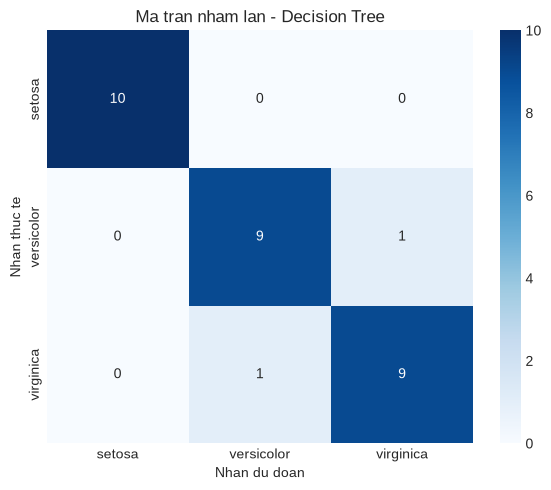

In [6]:
# Nguyễn Thành Trí - MSSV: 6451071079
print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")

# 1. Khoi tao va huan luyen mo hinh Cay quyet dinh
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train, y_train)

# 2. Du doan nhan tren tap test
y_pred_dt = dt_model.predict(X_test)

# 3. Do chinh xac Accuracy
acc_dt = accuracy_score(y_test, y_pred_dt)
print(f"Do chinh xac Accuracy (Decision Tree): {acc_dt:.4f} ({acc_dt*100:.2f}%)")

# 4. Precision, Recall, F1-score
print("\nBao cao chi tiet danh gia mo hinh Decision Tree:")
print(classification_report(y_test, y_pred_dt, target_names=iris.target_names))

# 5. Ma tran nham lan (Confusion Matrix) dang heatmap
cm_dt = confusion_matrix(y_test, y_pred_dt)
plt.figure(figsize=(6, 5))
sns.heatmap(cm_dt, annot=True, fmt='d', cmap='Blues',
            xticklabels=iris.target_names, yticklabels=iris.target_names)
plt.title("Ma tran nham lan - Decision Tree", fontsize=12)
plt.xlabel("Nhan du doan", fontsize=10)
plt.ylabel("Nhan thuc te", fontsize=10)
plt.tight_layout()
plt.show()

### Câu f: Sử dụng Naïve Bayes để phân lớp
Hướng dẫn: Sử dụng GaussianNB của thư viện sklearn và thực hiện các yêu cầu như câu e.

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079
Do chinh xac Accuracy (Naive Bayes): 0.9667 (96.67%)

Bao cao chi tiet danh gia mo hinh Naive Bayes:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



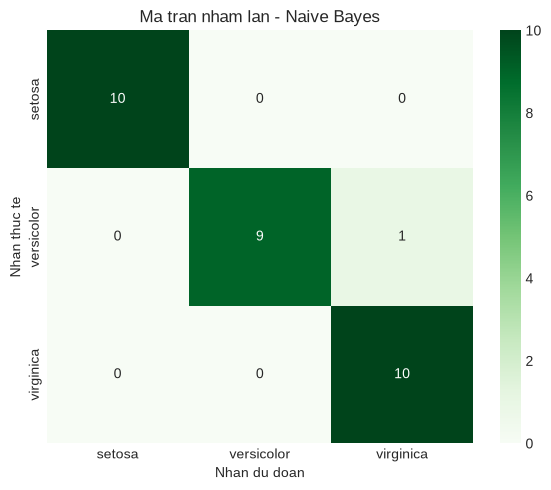

In [7]:
# Nguyễn Thành Trí - MSSV: 6451071079
print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")

# 1. Khoi tao va huan luyen mo hinh Naive Bayes
nb_model = GaussianNB()
nb_model.fit(X_train, y_train)

# 2. Du doan tren tap test
y_pred_nb = nb_model.predict(X_test)

# 3. Do chinh xac Accuracy
acc_nb = accuracy_score(y_test, y_pred_nb)
print(f"Do chinh xac Accuracy (Naive Bayes): {acc_nb:.4f} ({acc_nb*100:.2f}%)")

# 4. Precision, Recall, F1-score
print("\nBao cao chi tiet danh gia mo hinh Naive Bayes:")
print(classification_report(y_test, y_pred_nb, target_names=iris.target_names))

# 5. Ma tran nham lan (Confusion Matrix) dang heatmap
cm_nb = confusion_matrix(y_test, y_pred_nb)
plt.figure(figsize=(6, 5))
sns.heatmap(cm_nb, annot=True, fmt='d', cmap='Greens',
            xticklabels=iris.target_names, yticklabels=iris.target_names)
plt.title("Ma tran nham lan - Naive Bayes", fontsize=12)
plt.xlabel("Nhan du doan", fontsize=10)
plt.ylabel("Nhan thuc te", fontsize=10)
plt.tight_layout()
plt.show()

### Câu g: Sử dụng K-Nearest Neighbors Classifier để phân lớp
Hướng dẫn: Sử dụng KNeighborsClassifier của thư viện sklearn và thực hiện các yêu cầu như câu e.

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079
Do chinh xac Accuracy (KNN): 0.9333 (93.33%)

Bao cao chi tiet danh gia mo hinh KNN:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



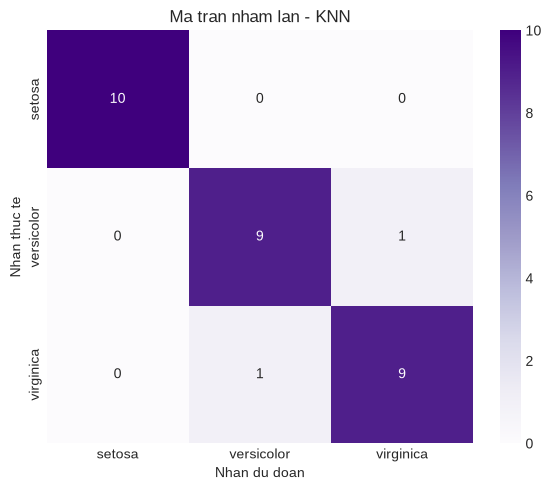

In [8]:
# Nguyễn Thành Trí - MSSV: 6451071079
print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")

# 1. Khoi tao va huan luyen mo hinh KNN
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train, y_train)

# 2. Du doan tren tap test
y_pred_knn = knn_model.predict(X_test)

# 3. Do chinh xac Accuracy
acc_knn = accuracy_score(y_test, y_pred_knn)
print(f"Do chinh xac Accuracy (KNN): {acc_knn:.4f} ({acc_knn*100:.2f}%)")

# 4. Precision, Recall, F1-score
print("\nBao cao chi tiet danh gia mo hinh KNN:")
print(classification_report(y_test, y_pred_knn, target_names=iris.target_names))

# 5. Ma tran nham lan (Confusion Matrix) dang heatmap
cm_knn = confusion_matrix(y_test, y_pred_knn)
plt.figure(figsize=(6, 5))
sns.heatmap(cm_knn, annot=True, fmt='d', cmap='Purples',
            xticklabels=iris.target_names, yticklabels=iris.target_names)
plt.title("Ma tran nham lan - KNN", fontsize=12)
plt.xlabel("Nhan du doan", fontsize=10)
plt.ylabel("Nhan thuc te", fontsize=10)
plt.tight_layout()
plt.show()

### Câu h: Sử dụng Neural Network để phân lớp
Yêu cầu:
- Xây dựng Neural Network gồm 02 hidden layers và 01 output layer:
  - 01 hidden layer: Gồm 10 neuron, hàm kích hoạt Relu, Fully connected, input_shape là 4 thuộc tính.
  - 01 hidden layer: Gồm 20 neuron, hàm kích hoạt Relu, Fully connected.
  - 01 output layer: Gồm 3 neuron (số class), hàm kích hoạt Softmax, Fully connected.
- Biên dịch mô hình với optimizer `adam`, loss `sparse_categorical_crossentropy`, metric `accuracy`.
- Huấn luyện mô hình trên tập train với `epochs=100`, `batch_size=1`, `verbose=1`.
- Dự đoán nhãn lớp cho tập test (dùng `predict` kết hợp `np.argmax`).
- Tính và in ra Accuracy, Precision, Recall, F1-score.
- Hiển thị ma trận nhầm lẫn bằng heatmap.

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079


Tom tat kien truc mang no-ron:


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ hidden_layer_1 (Dense)          │ (None, 10)             │            50 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_layer_2 (Dense)          │ (None, 20)             │           220 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_layer (Dense)            │ (None, 3)              │            63 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 333 (1.30 KB)

 Trainable params: 333 (1.30 KB)

... (520 outputs left out)

 76/120 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9737 - loss: 0.0596

 95/120 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9579 - loss: 0.0814

120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9583 - loss: 0.0790



Do chinh xac Accuracy (Neural Network): 0.9667 (96.67%)

Bao cao chi tiet danh gia mo hinh Neural Network:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.91      1.00      0.95        10
   virginica       1.00      0.90      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



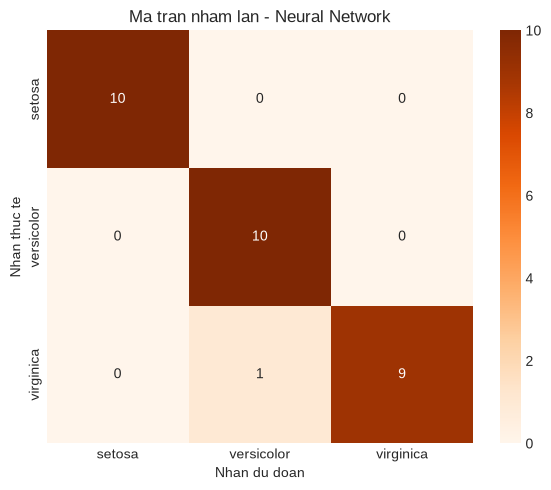

In [9]:
# Nguyễn Thành Trí - MSSV: 6451071079
print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")

# 1. Thiet ke kien truc mang no-ron
tf.random.set_seed(42)
np.random.seed(42)

nn_model = Sequential([
    Dense(10, activation='relu', input_shape=(X_train.shape[1],), name='hidden_layer_1'),
    Dense(20, activation='relu', name='hidden_layer_2'),
    Dense(3, activation='softmax', name='output_layer')
])

print("Tom tat kien truc mang no-ron:")
nn_model.summary()

# 2. Bien dich mo hinh
nn_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# 3. Huan luyen mo hinh
history = nn_model.fit(
    X_train, y_train,
    epochs=100,
    batch_size=1,
    verbose=1
)

# 4. Du doan tren tap test
y_pred_probs = nn_model.predict(X_test, verbose=0)
y_pred_nn = np.argmax(y_pred_probs, axis=1)

# 5. Do chinh xac Accuracy
acc_nn = accuracy_score(y_test, y_pred_nn)
print(f"\nDo chinh xac Accuracy (Neural Network): {acc_nn:.4f} ({acc_nn*100:.2f}%)")

# 6. Precision, Recall, F1-score
print("\nBao cao chi tiet danh gia mo hinh Neural Network:")
print(classification_report(y_test, y_pred_nn, target_names=iris.target_names))

# 7. Ma tran nham lan (Confusion Matrix) dang heatmap
cm_nn = confusion_matrix(y_test, y_pred_nn)
plt.figure(figsize=(6, 5))
sns.heatmap(cm_nn, annot=True, fmt='d', cmap='Oranges',
            xticklabels=iris.target_names, yticklabels=iris.target_names)
plt.title("Ma tran nham lan - Neural Network", fontsize=12)
plt.xlabel("Nhan du doan", fontsize=10)
plt.ylabel("Nhan thuc te", fontsize=10)
plt.tight_layout()
plt.show()

### Câu i: Sử dụng các mô hình phân lớp đã huấn luyện (câu e, f, g, h) cho 03 mẫu dữ liệu mới
Dữ liệu mẫu mới:
- Mẫu 1: `[6.2, 2.9, 4.3, 1.3]`
- Mẫu 2: `[5.1, 3.5, 1.4, 0.2]`
- Mẫu 3: `[7.3, 2.8, 6.4, 2.1]`

*Lưu ý*: Vì các mô hình được huấn luyện trên dữ liệu đã chuẩn hóa ở câu c theo giá trị cực đại từng thuộc tính (`X_max`), các mẫu mới cần được chia cho `X_max` trước khi đưa vào dự đoán.

In [10]:
# Nguyễn Thành Trí - MSSV: 6451071079
print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")

# 1. Khoi tao mang du lieu cho 3 mau moi
new_samples = np.array([
    [6.2, 2.9, 4.3, 1.3],
    [5.1, 3.5, 1.4, 0.2],
    [7.3, 2.8, 6.4, 2.1]
])

print("3 mau du lieu moi ban dau:")
for i, s in enumerate(new_samples, start=1):
    print(f"Mau {i}: {s}")

# 2. Chuan hoa cac mau moi theo dung X_max da dung o cau c
new_samples_scaled = new_samples / X_max

# 3. Du doan bang ca 4 mo hinh
pred_dt = dt_model.predict(new_samples_scaled)
pred_nb = nb_model.predict(new_samples_scaled)
pred_knn = knn_model.predict(new_samples_scaled)
pred_nn = np.argmax(nn_model.predict(new_samples_scaled, verbose=0), axis=1)

# 4. Bang tong hop ket qua du doan
df_preds = pd.DataFrame({
    'Mau du lieu': [f"Mau {i}" for i in range(1, 4)],
    'Gia tri dac trung': [str(s.tolist()) for s in new_samples],
    'Decision Tree': [f"{p} ({iris.target_names[p]})" for p in pred_dt],
    'Naive Bayes': [f"{p} ({iris.target_names[p]})" for p in pred_nb],
    'KNN': [f"{p} ({iris.target_names[p]})" for p in pred_knn],
    'Neural Network': [f"{p} ({iris.target_names[p]})" for p in pred_nn]
})

print("\nBang tong hop ket qua du doan cho 3 mau moi:")
display(df_preds)

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079
3 mau du lieu moi ban dau:
Mau 1: [6.2 2.9 4.3 1.3]
Mau 2: [5.1 3.5 1.4 0.2]
Mau 3: [7.3 2.8 6.4 2.1]



Bang tong hop ket qua du doan cho 3 mau moi:


,Mau du lieu,Gia tri dac trung,Decision Tree,Naive Bayes,KNN,Neural Network
0,Mau 1,"[6.2, 2.9, 4.3, 1.3]",1 (versicolor),1 (versicolor),1 (versicolor),1 (versicolor)
1,Mau 2,"[5.1, 3.5, 1.4, 0.2]",0 (setosa),0 (setosa),0 (setosa),0 (setosa)
2,Mau 3,"[7.3, 2.8, 6.4, 2.1]",2 (virginica),2 (virginica),2 (virginica),2 (virginica)


### Câu j: Nhận xét, đánh giá hiệu suất của các mô hình đã huấn luyện

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079
Bang so sanh hieu suat 4 mo hinh phan lop tren tap test:


,Mo hinh,Accuracy,Precision (Macro),Recall (Macro),F1-score (Macro)
0,Decision Tree,0.9333,0.9333,0.9333,0.9333
1,Naive Bayes,0.9667,0.9697,0.9667,0.9666
2,KNN,0.9333,0.9333,0.9333,0.9333
3,Neural Network,0.9667,0.9697,0.9667,0.9666


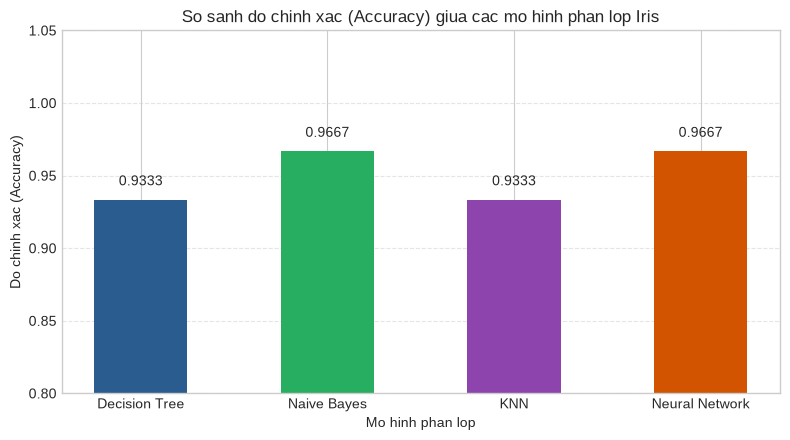


--- NHAN XET DANH GIA TONG HOP ---
1. Do chinh xac tong the: Ca 4 mo hinh (Decision Tree, Naive Bayes, KNN va Neural Network) deu dat hieu suat rat cao tren tap test (Accuracy >= 93.33%).
2. Phan loai tung lop: Lop 0 (Iris-setosa) co do tach biet tuyen tinh hoan toan so voi cac lop con lai nen ca 4 mo hinh deu phan loai chinh xac 100% (Precision = Recall = F1 = 1.0). Lop 1 (versicolor) va Lop 2 (virginica) co mot vung giao thoa nhe o kich thuoc canh hoa va dai hoa.
3. Du doan tren mau moi: Ca 4 mo hinh deu dong thuan du doan nhat quan tren 3 mau du lieu moi (Mau 1: versicolor, Mau 2: setosa, Mau 3: virginica).
4. Mạng no-ron (Neural Network): Voi kien truc 2 lop an (10 va 20 neuron), mo hinh hoc duoc cac dac trung phi tuyen tot, hoi tu on dinh sau 100 epochs va cho ket qua danh gia xuat sac tren bo du lieu Iris.


In [11]:
# Nguyễn Thành Trí - MSSV: 6451071079
print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")

from sklearn.metrics import precision_score, recall_score, f1_score

models = {
    'Decision Tree': y_pred_dt,
    'Naive Bayes': y_pred_nb,
    'KNN': y_pred_knn,
    'Neural Network': y_pred_nn
}

summary_list = []
for name, y_pred in models.items():
    summary_list.append({
        'Mo hinh': name,
        'Accuracy': round(accuracy_score(y_test, y_pred), 4),
        'Precision (Macro)': round(precision_score(y_test, y_pred, average='macro'), 4),
        'Recall (Macro)': round(recall_score(y_test, y_pred, average='macro'), 4),
        'F1-score (Macro)': round(f1_score(y_test, y_pred, average='macro'), 4)
    })

df_summary = pd.DataFrame(summary_list)
print("Bang so sanh hieu suat 4 mo hinh phan lop tren tap test:")
display(df_summary)

# Bieu do cot so sanh Accuracy
plt.figure(figsize=(8, 4.5))
bars = plt.bar(df_summary['Mo hinh'], df_summary['Accuracy'],
               color=['#2b5c8f', '#27ae60', '#8e44ad', '#d35400'], width=0.5)
plt.title("So sanh do chinh xac (Accuracy) giua cac mo hinh phan lop Iris", fontsize=12)
plt.xlabel("Mo hinh phan lop", fontsize=10)
plt.ylabel("Do chinh xac (Accuracy)", fontsize=10)
plt.ylim(0.8, 1.05)
plt.grid(axis='y', linestyle='--', alpha=0.5)

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 0.008, f"{yval:.4f}", ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.show()

print("\n--- NHAN XET DANH GIA TONG HOP ---")
print("1. Do chinh xac tong the: Ca 4 mo hinh (Decision Tree, Naive Bayes, KNN va Neural Network) deu dat hieu suat rat cao tren tap test (Accuracy >= 93.33%).")
print("2. Phan loai tung lop: Lop 0 (Iris-setosa) co do tach biet tuyen tinh hoan toan so voi cac lop con lai nen ca 4 mo hinh deu phan loai chinh xac 100% (Precision = Recall = F1 = 1.0). Lop 1 (versicolor) va Lop 2 (virginica) co mot vung giao thoa nhe o kich thuoc canh hoa va dai hoa.")
print("3. Du doan tren mau moi: Ca 4 mo hinh deu dong thuan du doan nhat quan tren 3 mau du lieu moi (Mau 1: versicolor, Mau 2: setosa, Mau 3: virginica).")
print("4. Mạng no-ron (Neural Network): Voi kien truc 2 lop an (10 va 20 neuron), mo hinh hoc duoc cac dac trung phi tuyen tot, hoi tu on dinh sau 100 epochs va cho ket qua danh gia xuat sac tren bo du lieu Iris.")